### Good executions vs. tips, revisited: aspects, events and soft labels

`good_tip_cca.ipynb` and `skillformer_goodtip.ipynb` treated each comment as a window labelled good or tip, and no
video model could tell them apart within a take (AUC ~0.51). The labels conflict: 26% of an expert's pauses have a
good execution **and** a tip at the identical timestamp (one spoken comment split into the two lists), and different
experts pause at the same events (median 2.8 s apart) and comment on different things. Polarity belongs to a
(moment, aspect) pair, not to a moment. This notebook:

1. **Aspects.** Splits every comment into sentences and tags each with the aspect it is about (one multiple-choice
   question per sentence to Qwen3.5-4B; a moment-level vocabulary per scenario, e.g. guide hand, elbow, follow-through,
   plant foot, bowing; plus generic pace / fluency / confidence and two non-specific options, *overall* and *other*).
   **How many conflicts are real?** Opposite-polarity sentences at the same pause or event that are about the
   *same* aspect, against a null that shuffles the aspect tags within scenario.
2. **Events and soft labels.** Pauses of all experts within 4 s are grouped into events. For each event and aspect,
   the label is the share of the commenting experts who praised it (each expert's vote = share of their sentences on
   that aspect that are good), a soft target in [0, 1].
3. **Video.** Frozen TimeSformer (K600, best exo camera, squashed frame, layer 12; per 1 s clip: CLS, patch mean,
   patch std), the best features of `timesformer_stage1.ipynb`. An event's window = the 7 clips from 6 s before to
   1 s after it.
   * **Event detection** (polarity ignored): can the video tell event windows from windows with no pause near them,
     within the same take? Against a position-in-take baseline.
   * **Event-weighted pooling for proficiency**: the detector (trained inside each fold) scores every window of every
     take; the token-std features are pooled over the top 25% windows, softmax-weighted, vs uniform (= stage 1),
     a random 25% and the bottom 75%. Same 4 x 5-fold CV and Spearman as before.
   * **Per-aspect polarity at events**: predict the soft label (binarized) per aspect from the event window,
     within aspect and within (take, aspect), folds by participant; against the take's other labels (person-level
     prior) and the **inter-expert ceiling** (one expert's vote predicting the others').

In [1]:
import ast
import json
from collections import Counter, defaultdict
from pathlib import Path

import av
import numpy as np

# Same takes as the earlier idea_1 notebooks: video and transcribed expert commentary, train / SkillFormer test split.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"
WINDOW_FPS = 1

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m):
    parts = m["video_paths"]["ego"].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def has_commentary(take):
    """Whether any expert recorded transcribed commentary on the take (the take set of the earlier notebooks)."""
    for data_path in (COMMENTARY_ROOT / take).rglob("data.json"):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        if any(transcripts.get(a.get("recording_path"), {}).get("text", "").strip() for a in data.get("annotations", [])):
            return True
    return False

def num_seconds(path):
    """Number of 1 FPS frames decode_1fps() gets from the video (frames 0, 30, 60, ... at 30 FPS)."""
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        step = round(float(stream.average_rate) / WINDOW_FPS)
        return (stream.frames - 1) // step + 1

with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m).exists() or not has_commentary(take_name(m)):
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"], "score": LEVELS[m["proficiency_score"]],
                      "participant": m["origin_participant_id"], "video": str(video_path(m)),
                      "seconds": num_seconds(video_path(m))})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
clip_of = {clip["take_name"]: clip for split_list in clips_by_split.values() for clip in split_list}
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} takes, {sum(c['seconds'] for c in split_list) / 3600:.1f} h of video")

# Good executions (polarity 1) and tips for improvement (polarity 0) of those takes. Each entry's "list" is a Python
# list literal of sentences (NaN for a few blank entries, which are dropped).
POLARITIES = {"good_executions": (1, "Good execution"), "tips_for_improvement": (0, "Tip for improvement")}

def entry_sentences(entry):
    if not isinstance(entry.get("list"), str):
        return []
    try:
        items = ast.literal_eval(entry["list"])
    except (ValueError, SyntaxError):
        items = [entry["list"]]
    return [s.strip() for s in (items if isinstance(items, list) else [items]) if isinstance(s, str) and s.strip()]

demonstration = {}
for annotation_file in ("proficiency_demonstration_train.json", "proficiency_demonstration_val.json"):
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        demonstration.update({take_name(m): m for m in json.load(file)["annotations"]})

moments = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        m = demonstration.get(clip["take_name"])
        for key, (polarity, tag) in POLARITIES.items():
            for entry in (m or {}).get(key, []):
                sentences = entry_sentences(entry)
                if sentences:
                    moments.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                                    "polarity": polarity, "time": float(entry["video_time"]), "expert": entry["expert_uid"],
                                    "text": f"{tag}: {' '.join(sentences)}"})
covered = {m["take_name"] for m in moments}
for split in ("train", "test"):
    split_moments = [m for m in moments if m["split"] == split]
    print(f"{split}: {sum(c['take_name'] in covered for c in clips_by_split[split])} takes with moments, "
          f"{sum(m['polarity'] for m in split_moments)} good executions, {sum(1 - m['polarity'] for m in split_moments)} tips; "
          f"scenarios {dict(Counter(m['scenario'] for m in split_moments))}")

train: 1174 takes, 36.3 h of video
test: 164 takes, 4.9 h of video
train: 371 takes with moments, 8241 good executions, 8326 tips; scenarios {'Cooking': 5033, 'Basketball': 7358, 'Dance': 1841, 'Music': 2228, 'Soccer': 107}
test: 61 takes with moments, 1315 good executions, 1161 tips; scenarios {'Basketball': 1315, 'Cooking': 481, 'Music': 264, 'Dance': 416}


#### 1. Sentences and their aspects

In [2]:
# Moment-level aspect vocabulary for good-execution / tip sentences, drafted from a sample of training comments.
# Each comment entry (one expert, one pause, one polarity) is split into sentences; each sentence gets one
# multiple-choice question (which aspect is it about?); the softmax over the option letters is kept. Polarity is not
# asked: it comes from the list the sentence is in. "overall" and "other" are not aspects of a specific movement and
# are left out of the aspect-level analyses.
import re
import string

ACTIVITY = {"Basketball": "basketball", "Cooking": "cooking", "Dance": "dance", "Music": "music (playing an instrument)",
            "Rock Climbing": "bouldering (rock climbing)", "Soccer": "soccer"}

MOMENT_ASPECTS = {
    "Basketball": {
        "footwork": "footwork and steps (which foot, stride, take-off foot)",
        "legs": "knee bend, legs and landing",
        "lift": "jump, lift and elevation",
        "balance": "balance and body momentum",
        "shooting hand": "shooting hand, wrist snap and release",
        "guide hand": "guide (non-shooting) hand",
        "elbow": "shooting elbow alignment",
        "ball position": "ball placement and protection (height, position relative to the shoulders)",
        "follow-through": "follow-through and extension toward the rim",
        "eyes": "eyes, vision and focus on the target",
        "shoulders": "shoulders and body squared to the target",
        "ball flight": "ball flight and result (arc, angle, power, make or miss)",
        "dribble": "dribbling, catching and handling the ball",
        "weak hand": "use of the weaker (off) hand",
    },
    "Cooking": {
        "knife": "knife skills and cutting (grip, cuts, size of pieces)",
        "tools": "choice and use of tools and cookware",
        "heat": "heat, temperature and cooking time",
        "ingredients": "ingredients, quantities and seasoning",
        "steps": "order of steps and method (following the recipe)",
        "handling": "stirring, flipping, pouring and handling food",
        "workspace": "organization and cleanliness of the workspace",
        "safety": "safety and hygiene",
        "result": "quality of the food (doneness, texture, appearance)",
    },
    "Dance": {
        "rhythm": "rhythm and timing with the music",
        "feet": "feet, toes and steps",
        "arms": "arms and upper body",
        "legs": "legs and knees",
        "balance": "weight transfer, balance and grounding",
        "turns": "turns and spins",
        "dynamics": "energy, sharpness and dynamics",
        "clarity": "clarity and precision of the movement",
        "choreography": "memory and knowledge of the choreography",
        "style": "style, expression and personal touches",
        "space": "use of space and changes of direction",
        "ease": "ease, relaxation and flow of movement",
    },
    "Music": {
        "notes": "correct notes, pitch and intonation",
        "tempo": "tempo and rhythm",
        "tone": "tone and sound quality",
        "bowing": "bowing, strumming or picking (bow placement, weight, speed, contact point)",
        "fingering": "fingering hand (finger placement, pressure, shifting)",
        "coordination": "coordination between the hands",
        "posture": "posture, hand position, tension and relaxation",
        "musicality": "phrasing, dynamics, articulation and expression",
    },
    "Rock Climbing": {
        "footwork": "footwork and foot placement",
        "hands": "hand holds and grip",
        "hips": "hip and body positioning",
        "tension": "body tension (keeping the feet on the wall)",
        "dynamic moves": "dynamic moves and momentum",
        "route reading": "route reading and decision making",
    },
    "Soccer": {
        "touch": "first touch and ball control",
        "contact": "contact point on the ball and striking technique",
        "plant foot": "non-kicking (plant) foot and leg",
        "knee": "knee bend and leg position",
        "posture": "body posture, center of gravity and balance",
        "arms": "use of the arms",
        "movement": "movement with the ball, footwork and agility",
        "eyes": "eyes and focus on the ball",
        "weak foot": "use of the weaker foot",
    },
}

GENERIC_ASPECTS = {
    "pace": "speed, pace and efficiency",
    "fluency": "flow and continuity (without stopping or hesitating)",
    "confidence": "confidence and comfort",
    "overall": "the performance in general (a general compliment or criticism with no specific aspect)",
    "other": "none of these (describes what is happening, or is not about the performance)",
}
NON_SPECIFIC = {"overall", "other"}

def aspects_for(scenario):
    """Ordered (name, description): scenario-specific aspects, then generic ones (ending with overall, other)."""
    return [*MOMENT_ASPECTS[scenario].items(), *GENERIC_ASPECTS.items()]

LETTERS = string.ascii_uppercase

def split_sentences(items):
    """List items -> sentences (items often hold several sentences)."""
    out = []
    for item in items:
        for s in re.split(r"(?<=[.!?])\s+", item.strip()):
            s = s.strip()
            if len(re.sub(r"[^A-Za-z]", "", s)) >= 3:
                out.append(s)
    return out

def aspect_prompt(scenario, polarity, sentence, context):
    kind = "praising something done well" if polarity == 1 else "giving a tip for improvement"
    options = "\n".join(f"{LETTERS[i]}. {d}" for i, (_, d) in enumerate(aspects_for(scenario)))
    ctx = f"The full comment was: \"{context}\"\n\n" if context != sentence else ""
    return (f"An expert watching a person's {ACTIVITY[scenario]} performance paused the video and made a comment "
            f"{kind}.\n\n{ctx}Which aspect of the performance is this sentence about?\n\"{sentence}\"\n\n"
            f"{options}\n\nChoose the most specific option that fits. Reply with exactly one letter.")


import torch
from tqdm.auto import tqdm

# Every sentence of every comment entry (one expert, one pause, one polarity), with its entry as context.
EMBEDDING_DIR = Path("embeddings")
participant_of = {c["take_name"]: c["participant"] for split_list in clips_by_split.values() for c in split_list}
sentence_rows = []
for take, m in demonstration.items():
    if take not in clip_of:
        continue
    for key, (polarity, _) in POLARITIES.items():
        for entry in m.get(key) or []:
            items = entry_sentences(entry)
            context = " ".join(items)
            for sentence in split_sentences(items):
                sentence_rows.append({"take_name": take, "scenario": clip_of[take]["scenario"],
                                      "participant": participant_of[take], "split": "test" if take in test_takes else "train",
                                      "expert": entry["expert_uid"], "time": float(entry["video_time"]),
                                      "polarity": polarity, "sentence": sentence, "context": context})
print(f"{len(sentence_rows)} sentences in {len({r['take_name'] for r in sentence_rows})} takes")

# Aspect of each sentence: one multiple-choice question to Qwen3.5-4B, softmax over the option letters' tokens.
ASPECT_SIGNATURE = json.dumps([MOMENT_ASPECTS, GENERIC_ASPECTS, aspect_prompt("Dance", 1, "SENTENCE", "CONTEXT")])
ASPECT_CACHE = EMBEDDING_DIR / "qwen35_goodtip_aspects.pt"
aspect_cache = torch.load(ASPECT_CACHE) if ASPECT_CACHE.exists() else {"vocabulary": ASPECT_SIGNATURE, "scores": {}}
assert aspect_cache["vocabulary"] == ASPECT_SIGNATURE, "vocabulary changed; delete the cache"
key_of = lambda r: (r["scenario"], r["polarity"], r["sentence"], r["context"])
todo = sorted({key_of(r) for r in sentence_rows} - set(aspect_cache["scores"]))
print(f"{len(todo)} distinct sentences to tag")
if todo:
    from transformers import AutoModelForMultimodalLM, AutoProcessor, BitsAndBytesConfig
    model_id = "Qwen/Qwen3.5-4B"
    bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.bfloat16,
                                    bnb_4bit_use_double_quant=True)
    model = AutoModelForMultimodalLM.from_pretrained(model_id, quantization_config=bnb_config, device_map="auto").eval()
    tokenizer = AutoProcessor.from_pretrained(model_id).tokenizer
    tokenizer.padding_side = "right"
    n_letters = max(len(aspects_for(s)) for s in MOMENT_ASPECTS)
    letter_ids = [tokenizer.encode(l, add_special_tokens=False)[0] for l in LETTERS[:n_letters]]
    assert all(len(tokenizer.encode(l, add_special_tokens=False)) == 1 for l in LETTERS[:n_letters])

    @torch.inference_mode()
    def letter_probabilities(keys):
        texts = [tokenizer.apply_chat_template([{"role": "user", "content": aspect_prompt(*k)}], tokenize=False,
                                               add_generation_prompt=True, enable_thinking=False) for k in keys]
        batch = tokenizer(texts, return_tensors="pt", padding=True).to(model.device)
        last = batch["attention_mask"].sum(1) - 1
        keep = torch.unique(last)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            logits = model(**batch, logits_to_keep=keep).logits
        rows = logits[torch.arange(len(texts)), torch.searchsorted(keep, last)].float()
        return [r[letter_ids[:len(aspects_for(k[0]))]].softmax(-1).cpu() for k, r in zip(keys, rows)]

    BATCH, CHUNK = 16, 2000
    todo.sort(key=lambda k: len(aspect_prompt(*k)))  # similar lengths per batch: little padding
    for start in tqdm(range(0, len(todo), CHUNK), desc="chunks of sentences"):
        keys = todo[start:start + CHUNK]
        for b in range(0, len(keys), BATCH):
            for k, p in zip(keys[b:b + BATCH], letter_probabilities(keys[b:b + BATCH])):
                aspect_cache["scores"][k] = p.half()
        torch.save(aspect_cache, ASPECT_CACHE)
    del model
    torch.cuda.empty_cache()
print(f"{len(aspect_cache['scores'])} tagged sentences in the cache")

43343 sentences in 432 takes


0 distinct sentences to tag
40279 tagged sentences in the cache


In [3]:
import pandas as pd

rows = pd.DataFrame(sentence_rows)
probabilities = [aspect_cache["scores"][key_of(r)].float().numpy() for r in sentence_rows]
rows["aspect"] = [aspects_for(s)[int(p.argmax())][0] for s, p in zip(rows.scenario, probabilities)]
rows["confidence"] = [float(p.max()) for p in probabilities]
rows["specific"] = ~rows.aspect.isin(NON_SPECIFIC)
rows["pause"] = rows.take_name + "|" + rows.expert + "|" + rows.time.round(2).astype(str)
print(f"{len(rows)} sentences, {rows.pause.nunique()} pauses, {rows.take_name.nunique()} takes; "
      f"{rows.specific.mean():.0%} tagged with a specific aspect; median tag confidence {rows.confidence.median():.2f}")
for scenario, group in rows.groupby("scenario"):
    counts = group.groupby("aspect").polarity.agg(["size", "mean"]).sort_values("size", ascending=False)
    print(f"\n{scenario} ({len(group)} sentences): aspect  n  (good share)")
    print("  " + "   ".join(f"{a} {int(n)} ({g:.2f})" for a, (n, g) in counts.iterrows()))
rng = np.random.default_rng(0)
print("\nRandom examples:")
for i in rng.choice(len(rows), 12, replace=False):
    r = rows.iloc[i]
    print(f"  [{r.scenario[:10]:<10} {'good' if r.polarity else 'tip ':<4}] {r.aspect:<15} {r.confidence:.2f}  {r.sentence[:100]}")

43343 sentences, 14034 pauses, 432 takes; 99% tagged with a specific aspect; median tag confidence 0.83

Basketball (22719 sentences): aspect  n  (good share)
  follow-through 4952 (0.71)   ball position 3056 (0.46)   lift 2898 (0.65)   footwork 1965 (0.50)   legs 1759 (0.41)   shooting hand 1327 (0.54)   guide hand 1296 (0.34)   ball flight 1275 (0.59)   balance 1132 (0.34)   eyes 1072 (0.73)   shoulders 695 (0.48)   elbow 664 (0.36)   dribble 282 (0.56)   pace 105 (0.36)   fluency 86 (0.37)   overall 78 (0.94)   weak hand 61 (0.51)   confidence 12 (0.67)   other 4 (0.00)

Cooking (8887 sentences): aspect  n  (good share)
  tools 1690 (0.43)   heat 1138 (0.44)   ingredients 1094 (0.51)   knife 1086 (0.59)   handling 966 (0.66)   result 847 (0.45)   pace 558 (0.59)   workspace 520 (0.41)   safety 327 (0.19)   overall 276 (0.74)   steps 156 (0.31)   confidence 128 (0.65)   other 51 (0.25)   fluency 50 (0.84)

Dance (6259 sentences): aspect  n  (good share)
  clarity 1571 (0.54)   arms 1

#### 2. How many conflicts are real?

* **Same expert, same pause**: pauses with both polarities; of their opposite-polarity sentence pairs (good x tip,
  both with a specific aspect), the share about the *same* aspect.
* **Different experts, same event**: the same share for opposite-polarity pairs from different experts at one event,
  and the expert agreement on an (event, aspect) when two or more experts comment on it (each expert's vote = share of
  their sentences on it that are good; pairs of votes on opposite sides of 0.5 disagree), with Cohen's kappa against
  the pooled vote balance.
* **Null**: aspect tags shuffled within scenario (200 times), which keeps how often each aspect is used.

In [4]:
EVENT_GAP = 4.0  # s from an event's first pause

# Events: all experts' pauses of a take, grouped greedily (a new event starts more than EVENT_GAP s after the current one's first pause).
pauses = rows.groupby("pause").agg(take_name=("take_name", "first"), time=("time", "first")).reset_index()
event_of = {}
for take, group in pauses.sort_values("time").groupby("take_name"):
    start, k = None, -1
    for pause, time in zip(group.pause, group.time):
        if start is None or time - start > EVENT_GAP:
            start, k = time, k + 1
        event_of[pause] = f"{take}#{k}"
rows["event"] = rows.pause.map(event_of)

scenario_codes = rows.scenario.astype("category").cat.codes.to_numpy()
pause_codes = rows.pause.astype("category").cat.codes.to_numpy()
event_codes = rows.event.astype("category").cat.codes.to_numpy()
expert_codes = rows.expert.astype("category").cat.codes.to_numpy()
polarity = rows.polarity.to_numpy()
aspect_names = sorted(rows.aspect.unique())
aspect_index = {a: i for i, a in enumerate(aspect_names)}
specific_index = np.array([a not in NON_SPECIFIC for a in aspect_names])

def same_aspect_share(aspect_codes, group_codes, cross_expert):
    """Of opposite-polarity sentence pairs (both specific) within a group, the share about the same aspect."""
    keep = specific_index[aspect_codes]
    g, a, p, e = group_codes[keep], aspect_codes[keep], polarity[keep], expert_codes[keep]
    if not cross_expert:
        frame = pd.DataFrame({"g": g, "a": a, "p": p})
        counts = frame.groupby(["g", "a", "p"]).size().unstack(fill_value=0)
        same = (counts[0] * counts[1]).sum() if 0 in counts and 1 in counts else 0
        totals = frame.groupby(["g", "p"]).size().unstack(fill_value=0)
        return same / max((totals[0] * totals[1]).sum(), 1)
    # Across experts: subtract the within-expert pairs from all pairs.
    frame = pd.DataFrame({"g": g, "a": a, "p": p, "e": e})
    def pairs(keys):
        c = frame.groupby(keys + ["p"]).size().unstack(fill_value=0)
        return (c.get(0, 0) * c.get(1, 0)).sum()
    same = pairs(["g", "a"]) - pairs(["g", "a", "e"])
    total = pairs(["g"]) - pairs(["g", "e"])
    return same / max(total, 1)

def agreement(aspect_codes, use_aspects=True):
    """Expert votes on (event, aspect) cells (or events) with 2+ experts: pairwise disagreement and Cohen's kappa."""
    keep = specific_index[aspect_codes] if use_aspects else np.ones(len(rows), bool)
    frame = pd.DataFrame({"cell": event_codes[keep] * (len(aspect_names) if use_aspects else 1) +
                                  (aspect_codes[keep] if use_aspects else 0),
                          "e": expert_codes[keep], "p": polarity[keep]})
    votes = frame.groupby(["cell", "e"]).p.mean().reset_index()
    votes = votes[votes.p != 0.5]
    votes["good"] = votes.p > 0.5
    per_cell = votes.groupby("cell").good.agg(["sum", "size"])
    per_cell = per_cell[per_cell["size"] >= 2]
    n_good, n = per_cell["sum"].to_numpy(), per_cell["size"].to_numpy()
    pairs = n * (n - 1) / 2
    agree = (n_good * (n_good - 1) / 2 + (n - n_good) * (n - n_good - 1) / 2).sum() / pairs.sum()
    p_good = n_good.sum() / n.sum()
    expected = p_good ** 2 + (1 - p_good) ** 2
    return {"cells": len(per_cell), "disagree": 1 - agree, "kappa": (agree - expected) / (1 - expected)}

observed_aspects = rows.aspect.map(aspect_index).to_numpy()
mixed = rows.groupby("pause").polarity.agg(lambda p: p.nunique() == 2)
print(f"Pauses with both polarities (one expert, one timestamp): {mixed.mean():.1%} of {len(mixed)}")
print(f"Events: {rows.event.nunique()} from {len(mixed)} pauses; experts per event "
      f"{dict(sorted(Counter(rows.groupby('event').expert.nunique()).items()))}")

def shuffled(rng):
    out = observed_aspects.copy()
    for s in np.unique(scenario_codes):
        idx = np.flatnonzero(scenario_codes == s)
        out[idx] = out[rng.permutation(idx)]
    return out

N_SHUFFLES = 200
rng = np.random.default_rng(0)
null_aspects = [shuffled(rng) for _ in range(N_SHUFFLES)]
conflict = {}
for label, group_codes, cross in [("same expert, same pause", pause_codes, False),
                                  ("different experts, same event", event_codes, True)]:
    obs = same_aspect_share(observed_aspects, group_codes, cross)
    null = np.array([same_aspect_share(a, group_codes, cross) for a in null_aspects])
    conflict[label] = (obs, null)
    print(f"\n{label}: opposite-polarity pairs about the same specific aspect {obs:.1%} "
          f"(shuffled aspects {null.mean():.1%} [{np.quantile(null, 0.025):.1%}, {np.quantile(null, 0.975):.1%}])")

agree_event = agreement(observed_aspects, use_aspects=False)
agree_aspect = agreement(observed_aspects)
agree_null = [agreement(a) for a in null_aspects[:50]]
print(f"\nExpert agreement on polarity, cells with 2+ experts voting:")
print(f"  per event (no aspects)       {agree_event['cells']:>5} events   disagree {agree_event['disagree']:.1%}   kappa {agree_event['kappa']:+.3f}")
print(f"  per (event, specific aspect) {agree_aspect['cells']:>5} cells    disagree {agree_aspect['disagree']:.1%}   kappa {agree_aspect['kappa']:+.3f}")
print(f"  ... with shuffled aspects    {np.mean([a['cells'] for a in agree_null]):>5.0f} cells    "
      f"disagree {np.mean([a['disagree'] for a in agree_null]):.1%}   kappa {np.mean([a['kappa'] for a in agree_null]):+.3f}")

Pauses with both polarities (one expert, one timestamp): 23.1% of 14034
Events: 6646 from 14034 pauses; experts per event {1: 3898, 2: 1703, 3: 705, 4: 292, 5: 48}



same expert, same pause: opposite-polarity pairs about the same specific aspect 18.0% (shuffled aspects 12.1% [11.6%, 12.6%])



different experts, same event: opposite-polarity pairs about the same specific aspect 12.4% (shuffled aspects 11.9% [11.6%, 12.1%])



Expert agreement on polarity, cells with 2+ experts voting:
  per event (no aspects)        2482 events   disagree 38.4%   kappa +0.231
  per (event, specific aspect)  3882 cells    disagree 39.5%   kappa +0.202
  ... with shuffled aspects     6126 cells    disagree 43.7%   kappa +0.124


#### 3. Soft labels per (event, aspect)

In [5]:
events = (rows.groupby("event")
          .agg(take_name=("take_name", "first"), scenario=("scenario", "first"), participant=("participant", "first"),
               split=("split", "first"), start=("time", "min"), end=("time", "max"), n_experts=("expert", "nunique"))
          .reset_index())
votes = rows[rows.specific].groupby(["event", "aspect", "expert"]).polarity.mean().rename("vote").reset_index()
cells_table = (votes.groupby(["event", "aspect"]).vote.agg(soft="mean", n_experts="size").reset_index()
               .merge(events[["event", "take_name", "scenario", "participant", "split", "start", "end"]], on="event"))
print(f"{len(events)} events in {events.take_name.nunique()} takes; span median {np.median(events.end - events.start):.1f} s; "
      f"{len(cells_table)} (event, aspect) cells, {(cells_table.n_experts >= 2).mean():.0%} with 2+ experts")
print("soft label: " + ", ".join(f"{k} {v:.0%}" for k, v in
      {"0 (all tips)": (cells_table.soft == 0).mean(), "1 (all good)": (cells_table.soft == 1).mean(),
       "exactly 0.5": (cells_table.soft == 0.5).mean(),
       "other mixed": ((cells_table.soft > 0) & (cells_table.soft < 1) & (cells_table.soft != 0.5)).mean()}.items()))
print(cells_table.groupby("scenario").agg(cells=("soft", "size"), events=("event", "nunique"), good=("soft", "mean")))

6646 events in 432 takes; span median 0.0 s; 17244 (event, aspect) cells, 19% with 2+ experts
soft label: 0 (all tips) 42%, 1 (all good) 43%, exactly 0.5 7%, other mixed 7%
            cells  events      good
scenario                           
Basketball   7456    1349  0.538190
Cooking      4383    2547  0.501123
Dance        2588     820  0.527276
Music        2729    1816  0.430684
Soccer         88      28  0.198657


#### 4. Video features: frozen TimeSformer windows

In [6]:
import gc

import torch
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score

all_clips = clips_by_split["train"] + clips_by_split["test"]
names = [c["take_name"] for c in all_clips]
scores = np.array([c["score"] for c in all_clips])
scenarios = np.array([c["scenario"] for c in all_clips])
participants = np.array([c["participant"] for c in all_clips])
SCENARIO_NAMES = np.unique(scenarios)

WINDOW = 7  # clips: 6 s before to 1 s after
ts = torch.load(EMBEDDING_DIR / "timesformer_k600_exo8fps_clips.pt")
window_features, take_mean = {}, {}
for t in names:
    x = ts["clips"]["squash"][t][:, 1].float().reshape(len(ts["clips"]["squash"][t]), -1).numpy()  # layer 12: (n, 2304)
    c = np.vstack([np.zeros((1, x.shape[1]), np.float32), np.cumsum(x, 0, dtype=np.float64)])
    j = np.arange(len(x))
    lo = np.maximum(0, j - WINDOW + 2)  # window ending at clip j + 1 (clamped): clips lo .. hi
    hi = np.minimum(len(x), j + 2)
    window_features[t] = ((c[hi] - c[lo]) / (hi - lo)[:, None]).astype(np.float32)  # window j: around time j s
    take_mean[t] = x.mean(0)
del ts
gc.collect()
STD = slice(1536, 2304)  # patch-token std part (the stage 1 best statistic)
n_windows = {t: len(w) for t, w in window_features.items()}

def window_at(take, time):
    return min(int(time), n_windows[take] - 1)
print(f"{sum(n_windows.values())} windows over {len(names)} takes")

147085 windows over 1338 takes


#### 5. Event detection: event windows vs. windows with no pause near them, within a take

In [7]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Positives: every event (window at its last pause). Negatives: windows whose time is more than WINDOW s from every
# pause of the take, as many as the take's events (or all there are).
rng = np.random.default_rng(0)
detect = []
pause_times = rows.groupby("take_name").time.apply(lambda s: np.unique(s.to_numpy()))
for take, group in events.groupby("take_name"):
    js = sorted({window_at(take, e) for e in group.end})
    detect += [(take, j, 1) for j in js]
    far = np.array([np.abs(j - pause_times[take]).min() > WINDOW for j in range(n_windows[take])])
    candidates = np.flatnonzero(far)
    for j in rng.choice(candidates, min(len(js), len(candidates)), replace=False):
        detect.append((take, int(j), 0))
detect = pd.DataFrame(detect, columns=["take_name", "j", "event"])
detect = detect.merge(events.groupby("take_name")[["scenario", "participant"]].first().reset_index(), on="take_name")
X_det = np.stack([window_features[t][j] - take_mean[t] for t, j in zip(detect.take_name, detect.j)])
position = np.stack([(detect.j / detect.take_name.map(n_windows)).to_numpy(),
                     np.log1p(detect.j.to_numpy())], 1)
position = np.hstack([position, position ** 2, pd.get_dummies(detect.scenario).to_numpy(float)])
y_det = detect.event.to_numpy()
print(f"{len(detect)} detection windows ({y_det.sum()} events, {(1 - y_det).sum()} non-events) in {detect.take_name.nunique()} takes")

from sklearn.compose import ColumnTransformer

N_VIDEO = X_det.shape[1]

def detector(with_position=False):
    """PCA-64 of the video features (position columns, if any, passed through after the PCA) -> logistic."""
    video_part = make_pipeline(StandardScaler(), PCA(64, svd_solver="full"))
    if with_position:
        video_part = ColumnTransformer([("video", video_part, slice(0, N_VIDEO)),
                                        ("position", StandardScaler(), slice(N_VIDEO, None))])
    return make_pipeline(video_part, StandardScaler(),
                         LogisticRegressionCV(Cs=np.logspace(-4, 1, 6), cv=3, max_iter=3000, n_jobs=-1))

detection_scores = {k: np.zeros(len(detect)) for k in ("video", "position", "video + position")}
folds = StratifiedGroupKFold(5, shuffle=True, random_state=0).split(X_det, y_det, detect.participant)
for fit, held in folds:
    detection_scores["video"][held] = detector().fit(X_det[fit], y_det[fit]).decision_function(X_det[held])
    p = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(position[fit], y_det[fit])
    detection_scores["position"][held] = p.decision_function(position[held])
    both = np.hstack([X_det, position])
    detection_scores["video + position"][held] = detector(True).fit(both[fit], y_det[fit]).decision_function(both[held])
detection_auc = {}
print(f"{'':<18}" + "".join(f"{s[:11]:>13}" for s in ["all", *sorted(detect.scenario.unique())]))
for key, s in detection_scores.items():
    detection_auc[key] = {"all": roc_auc_score(y_det, s)}
    for sc in sorted(detect.scenario.unique()):
        m = (detect.scenario == sc).to_numpy()
        detection_auc[key][sc] = roc_auc_score(y_det[m], s[m])
    print(f"{key:<18}" + "".join(f"{v:>13.3f}" for v in detection_auc[key].values()))

11620 detection windows (6630 events, 4990 non-events) in 432 takes


                            all   Basketball      Cooking        Dance        Music       Soccer
video                     0.724        0.860        0.711        0.896        0.640        0.835
position                  0.734        0.766        0.674        0.851        0.606        0.436
video + position          0.793        0.876        0.731        0.904        0.696        0.856


#### 6. Event-weighted pooling for proficiency (all 1,338 takes, 4 x 5-fold CV by participant)

In each fold the detector is trained on the training participants' detection windows only, then scores every window
of every take (no proficiency labels involved). Token-std features of the windows are pooled per take; each pooled
block is scenario-centered, PCA-64, plus the scenario one-hot; ridge for Spearman, logistic regression for accuracy.

In [8]:
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import OneHotEncoder

N_REPEATS, N_FOLDS, PCA_DIMS, TOP = 4, 5, 64, 0.25
POOLINGS = ["uniform (stage 1)", "top 25% event windows", "softmax over event score", "random 25%", "bottom 75%"]
log_duration = np.log([clip_of[t]["seconds"] for t in names])
std_windows = {t: window_features[t][:, STD] for t in names}
centered_windows = {t: window_features[t] - take_mean[t] for t in names}
random_order = {t: np.random.default_rng(i).permutation(n_windows[t]) for i, t in enumerate(names)}

def pooled(event_score):
    out = {k: [] for k in POOLINGS}
    for t in names:
        w, s = std_windows[t], event_score[t]
        k = max(1, int(round(TOP * len(w))))
        order = np.argsort(-s)
        out["uniform (stage 1)"].append(w.mean(0))
        out["top 25% event windows"].append(w[order[:k]].mean(0))
        weights = np.exp(s - s.max())
        out["softmax over event score"].append((weights[:, None] * w).sum(0) / weights.sum())
        out["random 25%"].append(w[random_order[t][:k]].mean(0))
        out["bottom 75%"].append(w[order[k:]].mean(0) if len(w) > k else w.mean(0))
    return {key: np.stack(v) for key, v in out.items()}

def centered(X, keys, fit):
    fit_rows = np.zeros(len(X), bool)
    fit_rows[fit] = True
    overall = X[fit_rows].mean(0)
    means = {k: X[fit_rows & (keys == k)].mean(0) if (fit_rows & (keys == k)).any() else overall for k in np.unique(keys)}
    return X - np.stack([means[k] for k in keys])

hits = defaultdict(lambda: np.full((N_REPEATS, len(names)), np.nan))
continuous = defaultdict(lambda: np.full((N_REPEATS, len(names)), np.nan))
fold_of = np.zeros((N_REPEATS, len(names)), int)
top_share_in_events = []
for repeat in range(N_REPEATS):
    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=repeat).split(np.zeros(len(names)), scores, participants)
    for fold, (fit, held) in enumerate(folds):
        fold_of[repeat, held] = fold
        fit_people = set(participants[fit])
        d_fit = detect.participant.isin(fit_people).to_numpy()
        det = detector().fit(X_det[d_fit], y_det[d_fit])
        event_score = {t: det.decision_function(centered_windows[t]) for t in names}
        features = pooled(event_score)
        onehot = OneHotEncoder(handle_unknown="ignore").fit(scenarios[fit][:, None]).transform(scenarios[:, None]).toarray()

        def run(key, X_features):
            X = np.hstack([onehot, X_features])
            probe = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=5, max_iter=5000, n_jobs=-1))
            hits[key][repeat, held] = probe.fit(X[fit], scores[fit]).predict(X[held]) == scores[held]
            ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 6, 17))).fit(X[fit], scores[fit])
            continuous[key][repeat, held] = ridge.predict(X[held])

        run("scenario only", np.zeros((len(names), 0)))
        duration = centered(log_duration[:, None], scenarios, fit)
        run("duration only", np.hstack([duration * (scenarios == s)[:, None] for s in SCENARIO_NAMES]))
        for key, X in features.items():
            Xc = centered(X, scenarios, fit)
            run(key, PCA(PCA_DIMS, svd_solver="full").fit(Xc[fit]).transform(Xc))
        # Held-out check: do the top-scored windows of held-out takes with events land near real pauses?
        for t in np.array(names)[held]:
            if t in pause_times.index:
                s = event_score[t]
                k = max(1, int(round(TOP * len(s))))
                near = np.array([np.abs(j - pause_times[t]).min() <= 3 for j in range(len(s))])
                top_share_in_events.append((near[np.argsort(-s)[:k]].mean(), near.mean()))
    print(f"repeat {repeat + 1} done")
top_share_in_events = np.array(top_share_in_events)
print(f"Held-out takes with pauses: share of top-25% windows within 3 s of a pause {top_share_in_events[:, 0].mean():.2f} "
      f"vs all windows {top_share_in_events[:, 1].mean():.2f}")

repeat 1 done


repeat 2 done


repeat 3 done


repeat 4 done
Held-out takes with pauses: share of top-25% windows within 3 s of a pause 0.71 vs all windows 0.62


In [9]:
N_BOOTSTRAP = 500
unique_participants = np.unique(participants)
rows_of = {p: np.flatnonzero(participants == p) for p in unique_participants}
boot = np.random.default_rng(0)
resamples = [np.concatenate([rows_of[p] for p in boot.choice(unique_participants, len(unique_participants))])
             for _ in range(N_BOOTSTRAP)]

def scenario_centered(values):
    out = values.astype(float).copy()
    for s in SCENARIO_NAMES:
        out[scenarios == s] -= values[scenarios == s].mean()
    return out

level_centered = scenario_centered(scores)

def within_fold_centered(c):
    out = c.copy()
    for r in range(N_REPEATS):
        for fold in np.unique(fold_of[r]):
            for s in SCENARIO_NAMES:
                group = (fold_of[r] == fold) & (scenarios == s)
                out[r, group] -= c[r, group].mean()
    return out.mean(0)

ordinal = {key: within_fold_centered(c) for key, c in continuous.items()}
per_take = {key: h.mean(0) for key, h in hits.items()}

def rho(key, rows_):
    a = ordinal[key][rows_]
    return spearmanr(a, level_centered[rows_])[0] if np.std(a) > 1e-9 else 0.0

ALL = np.ones(len(names), bool)
pool_spearman = {key: (rho(key, ALL), *np.quantile([rho(key, r) for r in resamples], [0.025, 0.975])) for key in ordinal}
print(f"{'pooling of token-std windows':<30}{'Spearman with level':>28}{'accuracy':>26}{'diff vs uniform':>30}")
for key in ["scenario only", "duration only", *POOLINGS]:
    s = pool_spearman[key]
    a = per_take[key].mean(), *np.quantile([per_take[key][r].mean() for r in resamples], [0.025, 0.975])
    d = np.array([rho(key, r) - rho("uniform (stage 1)", r) for r in resamples])
    diff = f"{s[0] - pool_spearman['uniform (stage 1)'][0]:+.3f} [{np.quantile(d, 0.025):+.3f}, {np.quantile(d, 0.975):+.3f}]" \
        if key in POOLINGS[1:] else ""
    print(f"{key:<30}{s[0]:>+10.3f} [{s[1]:+.3f}, {s[2]:+.3f}]{a[0]:>10.3f} [{a[1]:.3f}, {a[2]:.3f}]{diff:>30}")
print(f"\n{'per scenario':<30}" + "".join(f"{f'{s[:11]} ({(scenarios == s).sum()})':>18}" for s in SCENARIO_NAMES))
for key in POOLINGS:
    print(f"{key:<30}" + "".join(f"{rho(key, scenarios == s):>+18.2f}" for s in SCENARIO_NAMES))

pooling of token-std windows           Spearman with level                  accuracy               diff vs uniform
scenario only                     +0.000 [+0.000, +0.000]     0.400 [0.324, 0.481]                              


duration only                     +0.236 [+0.142, +0.326]     0.394 [0.333, 0.455]                              


uniform (stage 1)                 +0.465 [+0.332, +0.576]     0.443 [0.376, 0.519]                              


top 25% event windows             +0.476 [+0.349, +0.587]     0.458 [0.388, 0.532]       +0.012 [+0.002, +0.022]


softmax over event score          +0.472 [+0.341, +0.587]     0.447 [0.376, 0.521]       +0.008 [-0.000, +0.017]


random 25%                        +0.464 [+0.332, +0.575]     0.440 [0.373, 0.514]       -0.001 [-0.004, +0.002]


bottom 75%                        +0.461 [+0.328, +0.572]     0.444 [0.378, 0.519]       -0.004 [-0.007, -0.001]

per scenario                    Basketball (379)      Cooking (91)       Dance (290)       Music (118) Rock Climbi (413)       Soccer (47)
uniform (stage 1)                          +0.62             +0.25             +0.25             -0.06             +0.58             +0.19
top 25% event windows                      +0.62             +0.25             +0.28             +0.01             +0.58             +0.16
softmax over event score                   +0.62             +0.22             +0.27             +0.00             +0.57             +0.22
random 25%                                 +0.61             +0.25             +0.25             -0.06             +0.58             +0.22
bottom 75%                                 +0.62             +0.23             +0.24             -0.09             +0.58             +0.22


#### 7. Per-aspect polarity at events

Rows: (event, specific aspect) cells with a soft label other than exactly 0.5; target = soft label > 0.5 (the
experts who commented on it mostly praised it). Features: the event window (6 s before the event's first pause to 1 s
after its last), either **within-take centered** (the take's mean window subtracted: only what differs between moments
of one take) or **scenario-centered** (keeps person-level differences). One logistic model per scenario on the aspect
one-hot plus PCA-16 video features x aspect (each aspect gets its own video direction), 5 folds by participant.

Scored **within aspect** (AUC per aspect, weighted by cells) and **within (take, aspect)** (predictions centered within
each take and aspect, on the groups that have both outcomes: does the video tell which of one person's moments the
experts praised?). References: **take prior** (the take's other cells of the same aspect, label-only: person-level
skill) and the **inter-expert ceiling** (on cells with 2+ experts, one expert's vote predicting the others' majority).

For the within-take centered features only the within-(take, aspect) score answers a question: compared across takes,
their scores carry no person-level information, and their within-aspect AUC can drift below 0.5 (takes differ in how
many events they have and in their label balance), so it should not be read as signal.

In [10]:
VIDEO_DIMS = 16
cells_bin = cells_table[cells_table.soft != 0.5].reset_index(drop=True)
cells_bin["good"] = (cells_bin.soft > 0.5).astype(int)
def event_window(take, start, end):
    lo, hi = max(0, int(start) - WINDOW + 1), min(n_windows[take], int(end) + 2)
    return window_features[take][max(lo, 0):max(hi, lo + 1)].mean(0)
raw_window = np.stack([event_window(t, s, e) for t, s, e in zip(cells_bin.take_name, cells_bin.start, cells_bin.end)])
video = {"within-take": raw_window - np.stack([take_mean[t] for t in cells_bin.take_name]), "scenario-centered": raw_window}

def grouped_auc(y, s, groups, min_rows=20):
    """Cell-weighted mean of per-group AUCs (groups with both outcomes and min_rows rows)."""
    aucs, weights = [], []
    for g in np.unique(groups):
        m = groups == g
        if m.sum() >= min_rows and 0 < y[m].mean() < 1:
            aucs.append(roc_auc_score(y[m], s[m]))
            weights.append(m.sum())
    return np.average(aucs, weights=weights) if aucs else np.nan

def within_group_auc(y, s, groups):
    """AUC of scores centered within groups, on the groups that have both outcomes."""
    frame = pd.DataFrame({"y": y, "s": s, "g": groups})
    both = frame.groupby("g").y.transform(lambda v: 0 < v.mean() < 1).astype(bool)
    f = frame[both]
    return roc_auc_score(f.y, f.s - f.groupby("g").s.transform("mean")) if f.y.nunique() == 2 else np.nan, int(both.sum())

polarity_scores = {k: np.full(len(cells_bin), np.nan) for k in video}
for scenario, sub in cells_bin.groupby("scenario"):
    if len(sub) < 200 or sub.good.nunique() < 2 or sub.participant.nunique() < 5:
        continue
    idx = sub.index.to_numpy()
    aspects_here = sorted(sub.aspect.unique())
    A = (sub.aspect.to_numpy()[:, None] == np.array(aspects_here)[None]).astype(float)
    y = sub.good.to_numpy()
    for key, V in video.items():
        folds = StratifiedGroupKFold(5, shuffle=True, random_state=0).split(idx, y, sub.participant)
        for fit, held in folds:
            Vc = V[idx] - (V[idx][fit].mean(0) if key == "scenario-centered" else 0)
            Z = make_pipeline(StandardScaler(), PCA(VIDEO_DIMS, svd_solver="full")).fit(Vc[fit]).transform(Vc)
            X = np.hstack([A, (Z[:, :, None] * A[:, None, :]).reshape(len(Z), -1)])
            model = make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-4, 1, 6), cv=3, max_iter=3000, n_jobs=-1))
            polarity_scores[key][idx[held]] = model.fit(X[fit], y[fit]).decision_function(X[held])

# Take prior: mean label of the take's other cells with the same aspect (0.5 when none).
group_sum = cells_bin.groupby(["take_name", "aspect"]).good.transform("sum")
group_n = cells_bin.groupby(["take_name", "aspect"]).good.transform("size")
take_prior = np.where(group_n > 1, (group_sum - cells_bin.good) / (group_n - 1).clip(lower=1), 0.5)

# Inter-expert ceiling: each expert's vote vs. the majority of the others, on every cell with 2+ experts (including
# the cells whose soft label is exactly 0.5, i.e. the disagreements), in the modelled scenarios; others' ties dropped.
modelled_scenarios = set(cells_bin.scenario[~np.isnan(polarity_scores["within-take"])])
ve = votes.merge(cells_table[["event", "aspect", "take_name", "scenario"]], on=["event", "aspect"])
ve = ve[ve.scenario.isin(modelled_scenarios)]
ve = ve[ve.groupby(["event", "aspect"]).expert.transform("size") >= 2]
others = (ve.groupby(["event", "aspect"]).vote.transform("sum") - ve.vote) / (ve.groupby(["event", "aspect"]).vote.transform("size") - 1)
ceiling = ve.assign(others=others)[others != 0.5]
ceiling = ceiling.assign(target=(ceiling.others > 0.5).astype(int))

y_all = cells_bin.good.to_numpy()
aspect_groups = (cells_bin.scenario + "|" + cells_bin.aspect).to_numpy()
take_aspect_groups = (cells_bin.take_name + "|" + cells_bin.aspect).to_numpy()
modelled = ~np.isnan(polarity_scores["within-take"])
polarity_results = {}
print(f"{modelled.sum()} modelled cells ({cells_bin[modelled].scenario.value_counts().to_dict()}), good share {y_all[modelled].mean():.2f}")
print(f"{'':<34}{'within aspect':>16}{'within (take, aspect)':>26}")
for key, s in [("video, within-take centered", polarity_scores["within-take"]),
               ("video, scenario-centered", polarity_scores["scenario-centered"]), ("take prior (labels)", take_prior)]:
    m = modelled
    wa = grouped_auc(y_all[m], s[m], aspect_groups[m])
    wt, n_rows = within_group_auc(y_all[m], s[m], take_aspect_groups[m])
    polarity_results[key] = (wa, wt)
    print(f"{key:<34}{wa:>16.3f}{(f'{wt:.3f} ({n_rows} cells)' if key != 'take prior (labels)' else '-'):>26}")
c_aspect = (ceiling.scenario + "|" + ceiling.aspect).to_numpy()
# Within a take: does an expert's ranking of one person's moments (same aspect) match the other experts'? Groups are
# (take, aspect, expert); grouping by (take, aspect) alone would pit the two votes of one disagreeing cell against each other.
c_take = (ceiling.take_name + "|" + ceiling.aspect + "|" + ceiling.expert).to_numpy()
wa = grouped_auc(ceiling.target.to_numpy(), ceiling.vote.to_numpy(), c_aspect)
wt, n_rows = within_group_auc(ceiling.target.to_numpy(), ceiling.vote.to_numpy(), c_take)
polarity_results["inter-expert ceiling"] = (wa, wt)
print(f"{'inter-expert ceiling':<34}{wa:>16.3f}{f'{wt:.3f} ({n_rows} votes)':>26}")

print(f"\nPer scenario, within aspect (video within-take | scenario-centered | take prior):")
for scenario in sorted(cells_bin[modelled].scenario.unique()):
    m = modelled & (cells_bin.scenario == scenario).to_numpy()
    print(f"  {scenario:<12} {m.sum():>5} cells  " + "  ".join(
        f"{grouped_auc(y_all[m], s[m], aspect_groups[m]):.3f}"
        for s in (polarity_scores["within-take"], polarity_scores["scenario-centered"], take_prior)))
print(f"\nPer aspect (>= 100 cells), within aspect AUC, video within-take | scenario-centered | take prior:")
for g in sorted(np.unique(aspect_groups[modelled])):
    m = modelled & (aspect_groups == g)
    if m.sum() >= 100 and 0 < y_all[m].mean() < 1:
        print(f"  {g:<32} {m.sum():>5} cells, good {y_all[m].mean():.2f}:  " + "  ".join(
            f"{roc_auc_score(y_all[m], s[m]):.3f}" for s in (polarity_scores["within-take"], polarity_scores["scenario-centered"], take_prior)))

15986 modelled cells ({'Basketball': 6861, 'Cooking': 4064, 'Music': 2647, 'Dance': 2414}), good share 0.51
                                     within aspect     within (take, aspect)
video, within-take centered                  0.441       0.504 (10412 cells)


video, scenario-centered                     0.531       0.519 (10412 cells)
take prior (labels)                          0.685                         -


inter-expert ceiling                         0.626        0.550 (1908 votes)

Per scenario, within aspect (video within-take | scenario-centered | take prior):
  Basketball    6861 cells  0.406  0.586  0.736
  Cooking       4064 cells  0.499  0.538  0.613
  Dance         2414 cells  0.435  0.447  0.647
  Music         2647 cells  0.445  0.453  0.699

Per aspect (>= 100 cells), within aspect AUC, video within-take | scenario-centered | take prior:
  Basketball|balance                 406 cells, good 0.33:  0.508  0.661  0.691
  Basketball|ball flight             434 cells, good 0.57:  0.383  0.544  0.669
  Basketball|ball position           693 cells, good 0.51:  0.398  0.565  0.665
  Basketball|dribble                 164 cells, good 0.56:  0.464  0.503  0.759
  Basketball|elbow                   259 cells, good 0.37:  0.503  0.484  0.759
  Basketball|eyes                    456 cells, good 0.81:  0.326  0.640  0.673
  Basketball|follow-through          939 cells, good 0.73:  0.405  0.

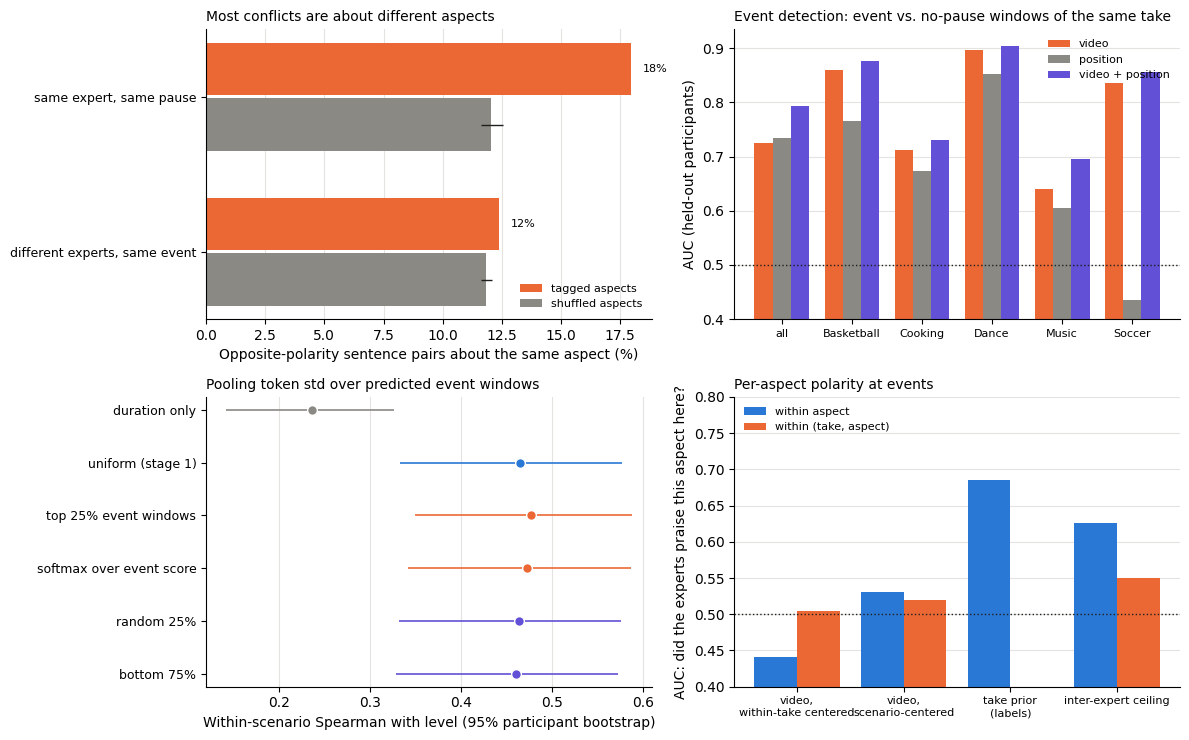

In [11]:
import matplotlib.pyplot as plt

GRID_COLOR, DARK, GRAY = "#e4e3df", "#1f1f1d", "#8a8984"
BLUE, ORANGE, GREEN, PURPLE = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"

def style(ax, axis="x"):
    ax.grid(axis=axis, color=GRID_COLOR, lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))

ax = axes[0, 0]
labels = list(conflict)
y = np.arange(len(labels))[::-1]
for yy, label in zip(y, labels):
    obs, null = conflict[label]
    ax.barh(yy + 0.18, obs * 100, height=0.34, color=ORANGE, label="tagged aspects" if yy == y[0] else None)
    ax.barh(yy - 0.18, null.mean() * 100, height=0.34, color=GRAY, label="shuffled aspects" if yy == y[0] else None,
            xerr=[[(null.mean() - np.quantile(null, 0.025)) * 100], [(np.quantile(null, 0.975) - null.mean()) * 100]],
            error_kw={"elinewidth": 1, "ecolor": DARK})
    ax.text(obs * 100 + 0.5, yy + 0.18, f"{obs:.0%}", va="center", fontsize=8)
ax.set_yticks(y, labels, fontsize=9)
ax.set_xlabel("Opposite-polarity sentence pairs about the same aspect (%)")
ax.set_title("Most conflicts are about different aspects", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8, loc="lower right")
style(ax)

ax = axes[0, 1]
keys = list(detection_auc)
groups = list(detection_auc[keys[0]])
x = np.arange(len(groups))
for i, (key, color) in enumerate(zip(keys, [ORANGE, GRAY, PURPLE])):
    ax.bar(x + (i - 1) * 0.26, [detection_auc[key][g] for g in groups], width=0.26, color=color, label=key)
ax.axhline(0.5, color=DARK, lw=1, ls=":")
ax.set_xticks(x, [g[:11] for g in groups], fontsize=8)
ax.set_ylim(0.4, max(0.8, max(max(v.values()) for v in detection_auc.values()) + 0.03))
ax.set_ylabel("AUC (held-out participants)")
ax.set_title("Event detection: event vs. no-pause windows of the same take", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8)
style(ax, "y")

ax = axes[1, 0]
keys = ["duration only", *POOLINGS]
y = np.arange(len(keys))[::-1]
for yy, key in zip(y, keys):
    s = pool_spearman[key]
    color = GRAY if key == "duration only" else BLUE if key.startswith("uniform") else ORANGE if "event" in key else PURPLE
    ax.errorbar(s[0], yy, xerr=[[s[0] - s[1]], [s[2] - s[0]]], fmt="o", ms=7, color=color, markeredgecolor="white",
                markeredgewidth=1, elinewidth=1.2)
ax.set_yticks(y, keys, fontsize=9)
ax.set_xlabel("Within-scenario Spearman with level (95% participant bootstrap)")
ax.set_title("Pooling token std over predicted event windows", loc="left", fontsize=10)
style(ax)

ax = axes[1, 1]
keys = list(polarity_results)
x = np.arange(len(keys))
ax.bar(x - 0.2, [polarity_results[k][0] for k in keys], width=0.4, color=BLUE, label="within aspect")
ax.bar(x + 0.2, [polarity_results[k][1] if k != "take prior (labels)" else np.nan for k in keys], width=0.4,
       color=ORANGE, label="within (take, aspect)")
ax.axhline(0.5, color=DARK, lw=1, ls=":")
ax.set_xticks(x, [k.replace(", ", ",\n").replace(" (", "\n(") for k in keys], fontsize=8)
ax.set_ylim(0.4, max(0.8, np.nanmax([v for k in keys for v in polarity_results[k]]) + 0.03))
ax.set_ylabel("AUC: did the experts praise this aspect here?")
ax.set_title("Per-aspect polarity at events", loc="left", fontsize=10)
ax.legend(frameon=False, fontsize=8)
style(ax, "y")

fig.tight_layout()
fig.savefig("figures/goodtip_aspects.png", dpi=200, bbox_inches="tight")
plt.show()